# Proyecto Final: Machine Learning aplicado a la Educación en Línea (OULAD)
**Maestría en IA, Educación e Investigación | Curso: Machine Learning**

---
## 📑 Tabla de Contenidos
1. [Introducción y Contexto](#1-introducción-y-contexto)
2. [Ingesta de Datos](#2-ingesta-de-datos)
3. [ETL (Extracción, Transformación y Carga)](#3-etl-extracción-transformación-y-carga)
4. [Análisis Exploratorio de Datos (EDA)](#4-análisis-exploratorio-de-datos-eda)
5. [Perfilado de Datos con YData Profiling](#5-perfilado-de-datos-con-ydata-profiling)
6. [Descripción de Variables](#6-descripción-de-variables)
7. [Modelo de Machine Learning (Tutorial)](#7-modelo-de-machine-learning-tutorial)
8. [Predicción con Nuevos Datos](#8-predicción-con-nuevos-datos)
9. [Simulador Interactivo (HTML/JS)](#9-simulador-interactivo-htmljs)
10. [Sumario de Procesos y Resultados](#10-sumario-de-procesos-y-resultados)
11. [Conclusiones](#11-conclusiones)

---
## 1. Introducción y Contexto
Este proyecto aborda la problemática de la **deserción y el rendimiento académico** en entornos de educación virtual. Utilizando el conjunto de datos **OULAD (Open University Learning Analytics Dataset)**, se busca construir un modelo de Machine Learning que prediga si un estudiante aprobará o reprobará/abandonará su curso basándose en su perfil demográfico y académico.

**Objetivo:** Desarrollar un clasificador supervisado que permita identificar estudiantes en riesgo de fracaso académico para intervenir oportunamente.

## 2. Ingesta de Datos
El primer paso es descargar el dataset desde Kaggle utilizando la librería `kagglehub` y cargarlo en memoria. El dataset OULAD contiene información sobre estudiantes, sus demografías y sus resultados finales.

In [1]:

%pip install -q kagglehub pandas numpy matplotlib seaborn scikit-learn


In [4]:

# ==================================================
# 2. INGESTA DE DATOS - DATASET OULAD
# Proyecto: Asistente de IA para Planificación Docente
# ==================================================

import kagglehub
import pandas as pd
import numpy as np
import os
import glob

print("INICIANDO INGESTA DE DATOS")
print("-" * 45)

# 1. Buscar primero si el dataset ya está en Colab
rutas_locales = glob.glob(
    "/content/**/studentInfo.csv",
    recursive=True
)

if rutas_locales:
    archivo = rutas_locales[0]
    print("Dataset encontrado en Google Colab.")

else:
    # 2. Descargar desde Kaggle si no está disponible
    print("Descargando dataset desde Kaggle...")

    path = kagglehub.dataset_download(
        "anlgrbz/student-demographics-online-education-dataoulad"
    )

    archivos = glob.glob(
        os.path.join(path, "**", "studentInfo.csv"),
        recursive=True
    )

    if not archivos:
        raise FileNotFoundError(
            "No se encontró studentInfo.csv. "
            "Verifica el contenido del dataset."
        )

    archivo = archivos[0]

# 3. Cargar dataset principal
df_raw = pd.read_csv(archivo)

# 4. Validar variable objetivo
if "final_result" not in df_raw.columns:
    raise ValueError(
        "El archivo no contiene la columna final_result."
    )

# 5. Mostrar información
print("\nArchivo cargado:", os.path.basename(archivo))
print("Ruta:", archivo)
print("Registros:", df_raw.shape[0])
print("Columnas:", df_raw.shape[1])

print("\nVARIABLES DISPONIBLES")
print(df_raw.columns.tolist())

print("\nPRIMEROS REGISTROS")
display(df_raw.head())

print("\nINGESTA DE DATOS COMPLETADA")


INICIANDO INGESTA DE DATOS
---------------------------------------------
Descargando dataset desde Kaggle...
Using Colab cache for faster access to the 'student-demographics-online-education-dataoulad' dataset.

Archivo cargado: studentInfo.csv
Ruta: /kaggle/input/student-demographics-online-education-dataoulad/studentInfo.csv
Registros: 32593
Columnas: 12

VARIABLES DISPONIBLES
['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result']

PRIMEROS REGISTROS


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass



INGESTA DE DATOS COMPLETADA


## 3. ETL (Extracción, Transformación y Carga)
En esta etapa limpiaremos los datos, manejaremos valores faltantes, codificaremos variables categóricas y transformaremos la variable objetivo (`final_result`) en un problema de clasificación binaria:
- **1 (Éxito):** 'Pass', 'Distinction'
- **0 (Fracaso/Deserción):** 'Fail', 'Withdrawn'

In [5]:

# ====================================================
# 3. EXTRACCIÓN, TRANSFORMACIÓN Y CARGA (ETL)
# Proyecto: Asistente de IA para Planificación Docente
# Dataset: OULAD
# ====================================================

import pandas as pd
import numpy as np

# PASO 1. Verificar la ingesta de datos

if "df_raw" not in globals():
    raise ValueError(
        "No existe df_raw. Ejecuta primero la ingesta."
    )

if "final_result" not in df_raw.columns:
    raise ValueError(
        "El dataset no contiene final_result."
    )

# Crear copia para no modificar los datos originales
df = df_raw.copy()

print("DATOS ORIGINALES")
print("Registros:", df.shape[0])
print("Columnas:", df.shape[1])

# PASO 2. Eliminar identificadores

columnas_eliminar = [
    "code_module",
    "code_presentation",
    "id_student",
    "date_registration",
    "date_unregistration"
]

df.drop(
    columns=columnas_eliminar,
    errors="ignore",
    inplace=True
)

# PASO 3. Revisar valores faltantes

print("\nVALORES FALTANTES ANTES DE LIMPIEZA")
print(df.isnull().sum())

# Completar variables categóricas
for columna in ["imd_band", "age_band"]:
    if columna in df.columns:
        moda = df[columna].mode(dropna=True)

        if not moda.empty:
            df[columna] = df[columna].fillna(
                moda.iloc[0]
            )
        else:
            df[columna] = df[columna].fillna(
                "Desconocido"
            )

# PASO 4. Crear variable objetivo

mapeo_resultados = {
    "Pass": 1,
    "Distinction": 1,
    "Fail": 0,
    "Withdrawn": 0
}

df["target"] = df["final_result"].map(
    mapeo_resultados
)

# Comprobar categorías desconocidas
if df["target"].isnull().any():
    raise ValueError(
        "Existen resultados académicos no reconocidos."
    )

df.drop(
    columns=["final_result"],
    inplace=True
)

df["target"] = df["target"].astype(int)

# PASO 5. Normalizar discapacidad

if "disability" in df.columns:
    df["disability"] = df["disability"].replace({
        "N": "no",
        "Y": "yes"
    })

# PASO 6. Codificación categórica

categoricas = [
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "disability"
]

categoricas = [
    col for col in categoricas
    if col in df.columns
]

for col in categoricas:
    df[col] = df[col].fillna(
        "Desconocido"
    ).astype(str)

df = pd.get_dummies(
    df,
    columns=categoricas,
    drop_first=True,
    dtype=int
)

# PASO 7. Validar resultados

print("\nETL COMPLETADO CORRECTAMENTE")
print("Registros:", df.shape[0])
print("Columnas:", df.shape[1])

print("\nDISTRIBUCIÓN DE TARGET")
print(df["target"].value_counts())

print("\nVALORES FALTANTES RESTANTES")
print(df.isnull().sum().sum())

display(df.head())


DATOS ORIGINALES
Registros: 32593
Columnas: 12

VALORES FALTANTES ANTES DE LIMPIEZA
gender                     0
region                     0
highest_education          0
imd_band                1111
age_band                   0
num_of_prev_attempts       0
studied_credits            0
disability                 0
final_result               0
dtype: int64

ETL COMPLETADO CORRECTAMENTE
Registros: 32593
Columnas: 32

DISTRIBUCIÓN DE TARGET
target
0    17208
1    15385
Name: count, dtype: int64

VALORES FALTANTES RESTANTES
0


,num_of_prev_attempts,studied_credits,target,gender_M,region_East Midlands Region,region_Ireland,region_London Region,region_North Region,region_North Western Region,region_Scotland,...,imd_band_30-40%,imd_band_40-50%,imd_band_50-60%,imd_band_60-70%,imd_band_70-80%,imd_band_80-90%,imd_band_90-100%,age_band_35-55,age_band_55<=,disability_yes
0,0,240,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
1,0,60,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
2,0,60,0,0,0,0,0,0,1,0,...,1,0,0,0,0,0,0,1,0,1
3,0,60,1,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,1,0,0
4,0,60,1,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [6]:
# Verificar si quedan valores nulos en el DataFrame limpio 'df'
print("Valores nulos por columna en el DataFrame limpio:")
display(df.isnull().sum())

Valores nulos por columna en el DataFrame limpio:


,0
num_of_prev_attempts,0
studied_credits,0
target,0
gender_M,0
region_East Midlands Region,0
region_Ireland,0
region_London Region,0
region_North Region,0
region_North Western Region,0
region_Scotland,0


/tmp/ipykernel_18761/1936566365.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df, palette='Set2')


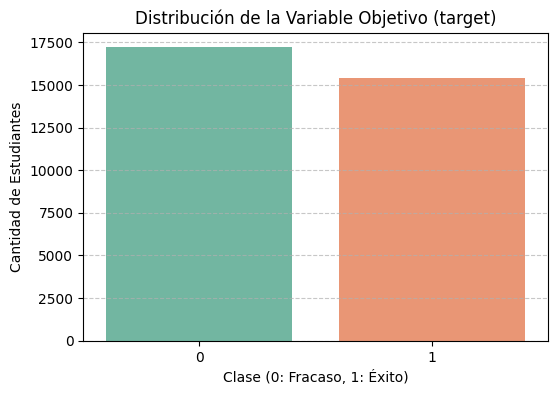

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualización de la distribución de la variable objetivo (target)
plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df, palette='Set2')
plt.title('Distribución de la Variable Objetivo (target)')
plt.xlabel('Clase (0: Fracaso, 1: Éxito)')
plt.ylabel('Cantidad de Estudiantes')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [8]:
# Calcular y mostrar la matriz de correlación de las variables numéricas en df
numeric_cols = df.select_dtypes(include=['number']).columns
corr_matrix = df[numeric_cols].corr()
print("Matriz de Correlación de las Variables Numéricas:")
display(corr_matrix)

Matriz de Correlación de las Variables Numéricas:


,num_of_prev_attempts,studied_credits,target,gender_M,region_East Midlands Region,region_Ireland,region_London Region,region_North Region,region_North Western Region,region_Scotland,...,imd_band_30-40%,imd_band_40-50%,imd_band_50-60%,imd_band_60-70%,imd_band_70-80%,imd_band_80-90%,imd_band_90-100%,age_band_35-55,age_band_55<=,disability_yes
num_of_prev_attempts,1.000000,0.181729,-0.105460,-0.025657,0.000240,0.009140,0.001730,-0.002104,-0.001870,0.003021,...,0.000277,-0.001378,-0.005847,-0.001160,-0.020041,-0.004094,-0.015981,0.014285,-0.010449,0.053691
studied_credits,0.181729,1.000000,-0.138630,0.018139,0.007892,-0.008162,0.025228,0.004177,0.006898,-0.023708,...,0.008630,0.007550,-0.016510,-0.022361,-0.018704,-0.010618,-0.012042,-0.070312,-0.008497,0.052240
target,-0.105460,-0.138630,1.000000,-0.022428,-0.008377,0.029928,-0.032162,0.016176,-0.043937,0.012067,...,-0.002080,-0.004087,0.010306,0.029495,0.026858,0.041762,0.060095,0.063331,0.023512,-0.059477
gender_M,-0.025657,0.018139,-0.022428,1.000000,-0.016408,0.002194,-0.012560,0.054790,0.019744,0.029897,...,0.000021,-0.013712,-0.008230,0.002339,0.024130,0.026617,0.042161,-0.042328,0.052080,-0.040032
region_East Midlands Region,0.000240,0.007892,-0.008377,-0.016408,1.000000,-0.054307,-0.092548,-0.068083,-0.087514,-0.096177,...,-0.001063,0.001475,0.004547,0.010049,-0.000377,0.021482,-0.004422,-0.007948,-0.022846,0.014547
region_Ireland,0.009140,-0.008162,0.029928,0.002194,-0.054307,1.000000,-0.064240,-0.047258,-0.060745,-0.066759,...,-0.019798,-0.024762,-0.003055,-0.010664,-0.009584,-0.009618,-0.012320,0.017837,-0.015858,-0.037630
region_London Region,0.001730,0.025228,-0.032162,-0.012560,-0.092548,-0.064240,1.000000,-0.080535,-0.103519,-0.113767,...,0.037302,-0.004211,-0.019309,-0.041394,-0.051146,-0.046373,-0.065381,0.027957,0.018623,-0.016053
region_North Region,-0.002104,0.004177,0.016176,0.054790,-0.068083,-0.047258,-0.080535,1.000000,-0.076154,-0.083693,...,-0.033451,-0.033446,-0.049316,-0.043338,-0.040007,-0.040025,-0.066714,-0.012251,0.004803,-0.043281
region_North Western Region,-0.001870,0.006898,-0.043937,0.019744,-0.087514,-0.060745,-0.103519,-0.076154,1.000000,-0.107578,...,0.002582,-0.022011,-0.013728,-0.029099,-0.023785,-0.039146,-0.058324,-0.011645,-0.004324,0.017418
region_Scotland,0.003021,-0.023708,0.012067,0.029897,-0.096177,-0.066759,-0.113767,-0.083693,-0.107578,1.000000,...,0.000586,0.005906,0.024304,0.023764,0.010411,0.021848,0.017460,0.030290,0.011268,0.012630


## 4. Análisis Exploratorio de Datos (EDA)
Realizamos un análisis visual para entender la distribución de las variables y su relación con la variable objetivo (`target`).

In [9]:

# Comprobar que el ETL se ejecutó correctamente

if "df" not in globals():
    print("ERROR: Primero debes ejecutar la ingesta y el ETL.")
else:
    print("DataFrame disponible:", df.shape)
    print("Variable objetivo disponible:", "target" in df.columns)
    display(df.head())


DataFrame disponible: (32593, 32)
Variable objetivo disponible: True


,num_of_prev_attempts,studied_credits,target,gender_M,region_East Midlands Region,region_Ireland,region_London Region,region_North Region,region_North Western Region,region_Scotland,...,imd_band_30-40%,imd_band_40-50%,imd_band_50-60%,imd_band_60-70%,imd_band_70-80%,imd_band_80-90%,imd_band_90-100%,age_band_35-55,age_band_55<=,disability_yes
0,0,240,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
1,0,60,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
2,0,60,0,0,0,0,0,0,1,0,...,1,0,0,0,0,0,0,1,0,1
3,0,60,1,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,1,0,0
4,0,60,1,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


Distribución de la variable target:
target
0    17208
1    15385
Name: count, dtype: int64


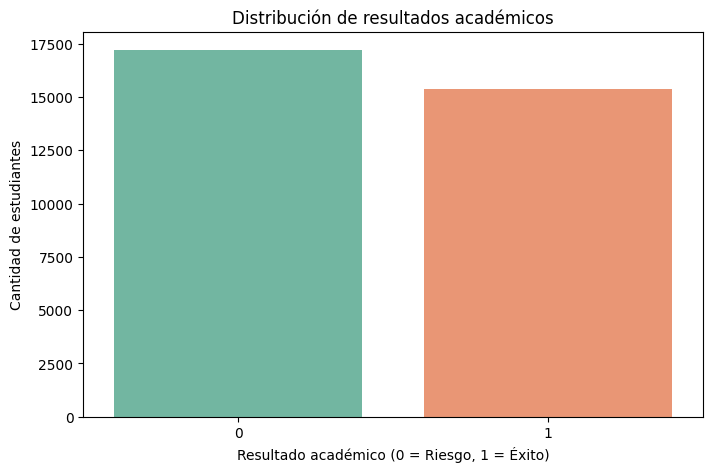

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

# Verificar distribución de la variable objetivo
print("Distribución de la variable target:")
print(df["target"].value_counts())

# Crear gráfico
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="target",
    hue="target",
    palette="Set2",
    legend=False
)

plt.title("Distribución de resultados académicos")
plt.xlabel("Resultado académico (0 = Riesgo, 1 = Éxito)")
plt.ylabel("Cantidad de estudiantes")

plt.show()


Dimensiones del DataFrame: (32593, 32)
Valores de target:
target
0    17208
1    15385
Name: count, dtype: int64


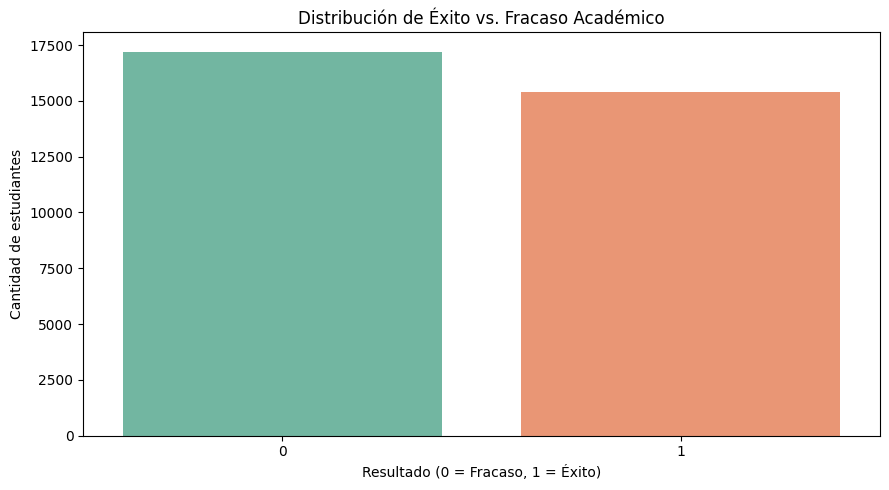

In [11]:

import matplotlib.pyplot as plt
import seaborn as sns

# Verificar que existen los datos
print("Dimensiones del DataFrame:", df.shape)
print("Valores de target:")
print(df["target"].value_counts())

# Gráfico de distribución de la variable objetivo
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="target",
    hue="target",
    palette="Set2",
    legend=False
)

plt.title("Distribución de Éxito vs. Fracaso Académico")
plt.xlabel("Resultado (0 = Fracaso, 1 = Éxito)")
plt.ylabel("Cantidad de estudiantes")

plt.tight_layout()
plt.show()


ANÁLISIS EXPLORATORIO DE DATOS
--------------------------------
Registros disponibles: 32593


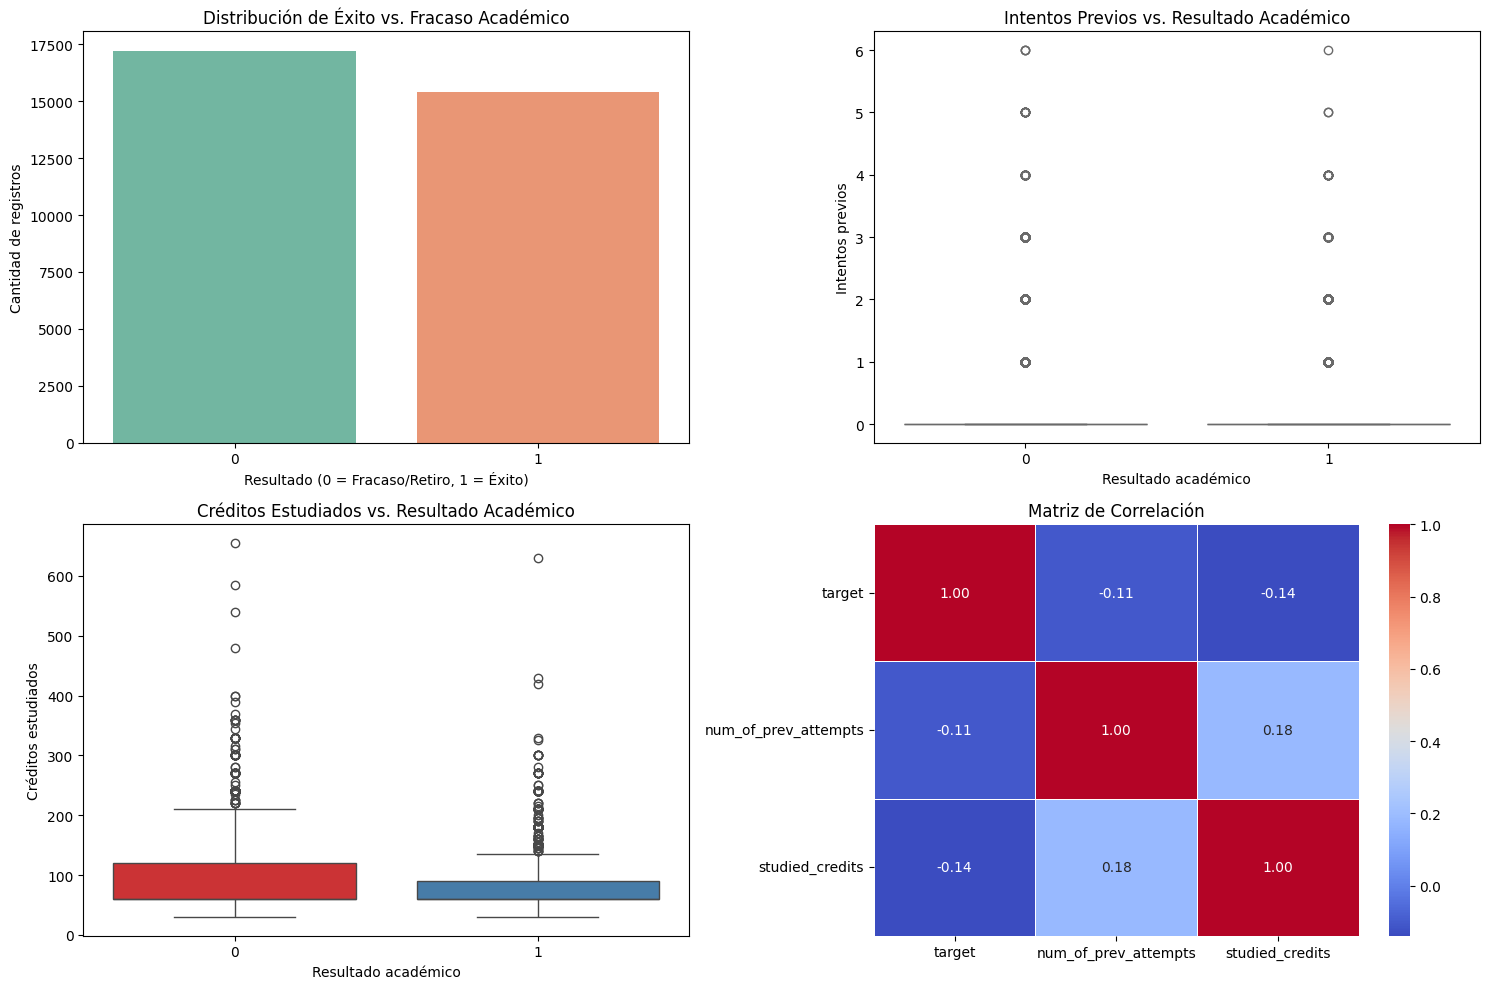


EDA ejecutado correctamente.


In [15]:

# ============================================================
# 4. ANÁLISIS EXPLORATORIO DE DATOS (EDA)
# Proyecto: Asistente de IA para la Planificación Docente
# Dataset: OULAD
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Verificar que el DataFrame existe
if "df" not in globals():
    raise ValueError(
        "El DataFrame 'df' no está definido. "
        "Ejecuta primero la ingesta de datos y el ETL."
    )

# 2. Comprobar las columnas necesarias
columnas_requeridas = [
    "target",
    "studied_credits"
]

faltantes = [
    col for col in columnas_requeridas
    if col not in df.columns
]

if faltantes:
    raise ValueError(
        f"Faltan columnas necesarias: {faltantes}"
    )

# 3. Identificar columna de intentos previos
if "num_of_prev_attempts" in df.columns:
    col_intentos = "num_of_prev_attempts"
elif "num_prev_attempts" in df.columns:
    col_intentos = "num_prev_attempts"
else:
    raise ValueError(
        "No se encontró la columna de intentos previos."
    )

# 4. Crear copia de las variables para el EDA
df_eda = df[
    ["target", col_intentos, "studied_credits"]
].copy()

# Convertir a valores numéricos
for columna in df_eda.columns:
    df_eda[columna] = pd.to_numeric(
        df_eda[columna],
        errors="coerce"
    )

# Eliminar filas incompletas solo para estos gráficos
df_eda = df_eda.dropna()

print("ANÁLISIS EXPLORATORIO DE DATOS")
print("--------------------------------")
print("Registros disponibles:", len(df_eda))

# 5. Crear las cuatro visualizaciones
fig, axes = plt.subplots(
    2, 2, figsize=(15, 10)
)

# GRÁFICO 1. Distribución de la variable objetivo
sns.countplot(
    data=df_eda,
    x="target",
    hue="target",
    palette="Set2",
    legend=False,
    ax=axes[0, 0]
)

axes[0, 0].set_title(
    "Distribución de Éxito vs. Fracaso Académico"
)
axes[0, 0].set_xlabel(
    "Resultado (0 = Fracaso/Retiro, 1 = Éxito)"
)
axes[0, 0].set_ylabel(
    "Cantidad de registros"
)

# GRÁFICO 2. Intentos previos vs. resultado
sns.boxplot(
    data=df_eda,
    x="target",
    y=col_intentos,
    hue="target",
    palette="Set3",
    legend=False,
    ax=axes[0, 1]
)

axes[0, 1].set_title(
    "Intentos Previos vs. Resultado Académico"
)
axes[0, 1].set_xlabel("Resultado académico")
axes[0, 1].set_ylabel("Intentos previos")

# GRÁFICO 3. Créditos estudiados vs. resultado
sns.boxplot(
    data=df_eda,
    x="target",
    y="studied_credits",
    hue="target",
    palette="Set1",
    legend=False,
    ax=axes[1, 0]
)

axes[1, 0].set_title(
    "Créditos Estudiados vs. Resultado Académico"
)
axes[1, 0].set_xlabel("Resultado académico")
axes[1, 0].set_ylabel("Créditos estudiados")

# GRÁFICO 4. Matriz de correlación
correlaciones = df_eda[
    ["target", col_intentos, "studied_credits"]
].corr()

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    ax=axes[1, 1]
)

axes[1, 1].set_title(
    "Matriz de Correlación"
)

# 6. Mostrar gráficos
plt.tight_layout()
plt.show()

print("\nEDA ejecutado correctamente.")


### Evaluación del Rendimiento del Modelo (Model Performance Evaluation)
Calcularemos métricas clave como Accuracy, Precision, Recall, F1-Score y ROC-AUC, y visualizaremos la matriz de confusión para entender detalladamente el rendimiento del clasificador sobre los datos de prueba.

In [23]:

# Verificar los datos disponibles en memoria

variables = [
    "df_raw",
    "df",
    "X",
    "y",
    "X_train",
    "X_test",
    "X_train_scaled",
    "X_test_scaled",
    "y_train",
    "y_test",
    "rf_model"
]

print("ESTADO ACTUAL DEL PROYECTO")
print("-" * 45)

for variable in variables:
    if variable in globals():
        print(f"✅ DISPONIBLE: {variable}")
    else:
        print(f"❌ FALTA: {variable}")


ESTADO ACTUAL DEL PROYECTO
---------------------------------------------
✅ DISPONIBLE: df_raw
✅ DISPONIBLE: df
✅ DISPONIBLE: X
✅ DISPONIBLE: y
✅ DISPONIBLE: X_train
✅ DISPONIBLE: X_test
✅ DISPONIBLE: X_train_scaled
✅ DISPONIBLE: X_test_scaled
✅ DISPONIBLE: y_train
✅ DISPONIBLE: y_test
✅ DISPONIBLE: rf_model


In [26]:

# ==================================================
# 5. PREPARACIÓN DE DATOS PARA MACHINE LEARNING
# ==================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

# Verificar variable objetivo
if "target" not in df.columns:
    raise ValueError(
        "No se encontró la variable target en df."
    )

# Separar variables predictoras y objetivo
X = df.drop(columns=["target"]).copy()
y = df["target"].copy()

# Verificar que las variables sean numéricas
columnas_no_numericas = X.select_dtypes(
    exclude=["number", "bool"]
).columns.tolist()

if columnas_no_numericas:
    raise ValueError(
        f"Existen variables no numéricas: {columnas_no_numericas}"
    )

# Dividir los datos: 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Escalar las variables
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("PREPARACIÓN COMPLETADA")
print("Variables predictoras:", X.shape[1])
print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)


PREPARACIÓN COMPLETADA
Variables predictoras: 31
Datos de entrenamiento: (26074, 31)
Datos de prueba: (6519, 31)


In [22]:

# ==================================================
# ENTRENAMIENTO DEL MODELO RANDOM FOREST
# Proyecto: Asistente de IA para Planificación Docente
# ==================================================

from sklearn.ensemble import RandomForestClassifier

# Crear el modelo
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Entrenar con los datos preparados
rf_model.fit(X_train_scaled, y_train)

# Verificar entrenamiento
print("✅ Random Forest entrenado correctamente.")
print("Número de árboles:", rf_model.n_estimators)
print("Número de variables:", rf_model.n_features_in_)
print("Clases identificadas:", rf_model.classes_)


✅ Random Forest entrenado correctamente.
Número de árboles: 100
Número de variables: 31
Clases identificadas: [0 1]


In [27]:

# DIAGNÓSTICO DEL PROYECTO

variables = [
    "df",
    "X",
    "y",
    "X_train_scaled",
    "X_test_scaled",
    "y_train",
    "y_test",
    "rf_model",
    "y_pred"
]

print("DIAGNÓSTICO DE VARIABLES")
print("-" * 40)

for nombre in variables:
    if nombre in globals():
        print(f"✅ {nombre}: DISPONIBLE")
    else:
        print(f"❌ {nombre}: NO DISPONIBLE")

if "df" in globals():
    print("\nDimensiones de df:", df.shape)
    print("¿Existe target?:", "target" in df.columns)


DIAGNÓSTICO DE VARIABLES
----------------------------------------
✅ df: DISPONIBLE
✅ X: DISPONIBLE
✅ y: DISPONIBLE
✅ X_train_scaled: DISPONIBLE
✅ X_test_scaled: DISPONIBLE
✅ y_train: DISPONIBLE
✅ y_test: DISPONIBLE
✅ rf_model: DISPONIBLE
❌ y_pred: NO DISPONIBLE

Dimensiones de df: (32593, 32)
¿Existe target?: True


In [28]:

# Verificar las variables necesarias para evaluar el modelo

variables = [
    "rf_model",
    "X_train_scaled",
    "X_test_scaled",
    "y_train",
    "y_test"
]

for variable in variables:
    if variable in globals():
        print(f"OK: {variable} está disponible")
    else:
        print(f"FALTA: {variable}")


OK: rf_model está disponible
OK: X_train_scaled está disponible
OK: X_test_scaled está disponible
OK: y_train está disponible
OK: y_test está disponible


In [75]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Generar predicciones
y_pred = rf_model.predict(X_test_scaled)

# Obtener probabilidades
y_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

# Calcular métricas
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("RESULTADOS DEL MODELO RANDOM FOREST")
print("----------------------------------")
print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")
print(f"F1-score:  {f1:.2%}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nREPORTE DE CLASIFICACIÓN")
print(classification_report(y_test, y_pred))


RESULTADOS DEL MODELO RANDOM FOREST
----------------------------------
Accuracy:  60.55%
Precision: 57.54%
Recall:    62.66%
F1-score:  59.99%
ROC-AUC:   0.6481

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

           0       0.64      0.59      0.61      3442
           1       0.58      0.63      0.60      3077

    accuracy                           0.61      6519
   macro avg       0.61      0.61      0.61      6519
weighted avg       0.61      0.61      0.61      6519



In [29]:

# ==================================================
# GENERACIÓN DE PREDICCIONES - RANDOM FOREST
# ==================================================

# Realizar predicciones con el modelo entrenado
y_pred = rf_model.predict(X_test_scaled)

# Comprobar resultados
print("✅ Predicciones generadas correctamente")
print("Total de predicciones:", len(y_pred))

print("\nPrimeras 10 predicciones:")
print(y_pred[:10])

print("\nPrimeros 10 valores reales:")
print(y_test.iloc[:10].values)


✅ Predicciones generadas correctamente
Total de predicciones: 6519

Primeras 10 predicciones:
[0 1 1 0 1 0 0 1 0 1]

Primeros 10 valores reales:
[0 0 0 0 1 1 0 1 0 0]


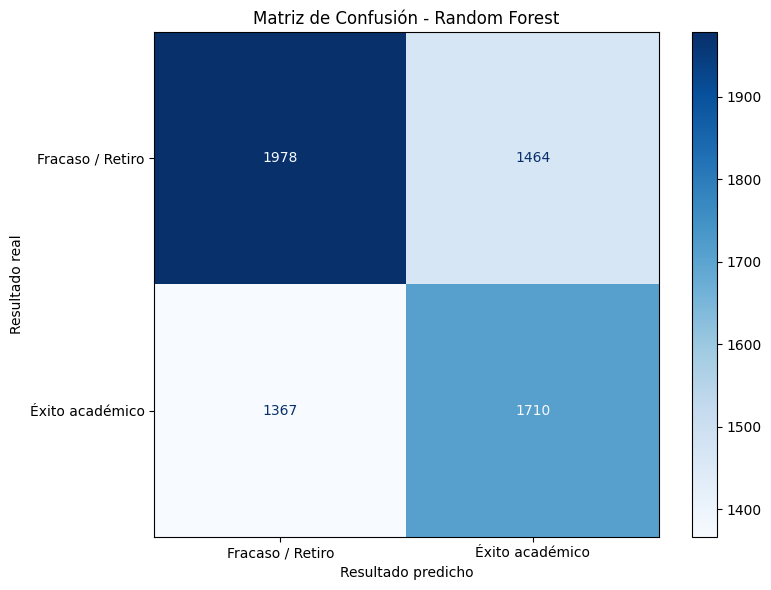

✅ Matriz de confusión generada correctamente.


In [31]:

# ==================================================
# MATRIZ DE CONFUSIÓN - RANDOM FOREST
# Proyecto: Asistente de IA para Planificación Docente
# ==================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Generar las predicciones
y_pred = rf_model.predict(X_test_scaled)

# Crear figura
fig, ax = plt.subplots(figsize=(8, 6))

# Generar matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_true=y_test,
    y_pred=y_pred,
    labels=[0, 1],
    display_labels=[
        "Fracaso / Retiro",
        "Éxito académico"
    ],
    cmap="Blues",
    values_format="d",
    ax=ax
)

# Personalizar gráfico
ax.set_title("Matriz de Confusión - Random Forest")
ax.set_xlabel("Resultado predicho")
ax.set_ylabel("Resultado real")

plt.tight_layout()
plt.show()

print("✅ Matriz de confusión generada correctamente.")


In [34]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predicciones del modelo entrenado
y_pred = rf_model.predict(X_test_scaled)
y_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

# Evaluación
print("EVALUACIÓN DEL MODELO RANDOM FOREST")

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred))

print("Recall:",
      recall_score(y_test, y_pred))

print("F1-score:",
      f1_score(y_test, y_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob))

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred))


EVALUACIÓN DEL MODELO RANDOM FOREST
Accuracy: 0.5657309403282712
Precision: 0.5387523629489603
Recall: 0.5557361065973351
F1-score: 0.547112462006079
ROC-AUC: 0.5856298355760164

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.59      0.57      0.58      3442
           1       0.54      0.56      0.55      3077

    accuracy                           0.57      6519
   macro avg       0.57      0.57      0.56      6519
weighted avg       0.57      0.57      0.57      6519



### 🛠️ Estrategia de Mejora 1: Optimización de Hiperparámetros del Random Forest
Utilizaremos `RandomizedSearchCV` para buscar una configuración óptima de hiperparámetros (como la profundidad máxima del árbol, el número mínimo de muestras por división, etc.), lo que ayuda a reducir el subajuste (underfitting) y sobreajuste (overfitting).

In [35]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

# Definir la cuadrícula de parámetros a explorar
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': ['balanced', 'balanced_subsample']
}

# Configurar la búsqueda aleatoria con validación cruzada (3 folds para velocidad)
rf_random = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1
)

print("Buscando los mejores hiperparámetros para RandomForest...")
rf_random.fit(X_train_scaled, y_train)

print("✔ ¡Búsqueda completada!")
print("Mejores parámetros encontrados:", rf_random.best_params_)

# Evaluar el modelo optimizado
best_rf_model = rf_random.best_estimator_
y_pred_opt = best_rf_model.predict(X_test_scaled)
y_prob_opt = best_rf_model.predict_proba(X_test_scaled)[:, 1]

from sklearn.metrics import accuracy_score, roc_auc_score
print(f"Nuevo Accuracy: {accuracy_score(y_test, y_pred_opt):.4f} (Anterior: 0.6055)")
print(f"Nuevo ROC-AUC: {roc_auc_score(y_test, y_prob_opt):.4f} (Anterior: 0.6481)")

Buscando los mejores hiperparámetros para RandomForest...
✔ ¡Búsqueda completada!
Mejores parámetros encontrados: {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_depth': 10, 'class_weight': 'balanced'}
Nuevo Accuracy: 0.6087 (Anterior: 0.6055)
Nuevo ROC-AUC: 0.6503 (Anterior: 0.6481)


### 🚀 Estrategia de Mejora 2: Uso de LightGBM (Gradient Boosting)
Los algoritmos de Gradient Boosting suelen tener un desempeño superior en datos tabulares complejos. Probaremos con **LightGBM**, un modelo sumamente rápido y eficiente.

In [36]:
import lightgbm as lgb
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# Configurar y entrenar el modelo LightGBM
lgb_model = lgb.LGBMClassifier(
    n_estimators=150,
    learning_rate=0.05,
    num_leaves=31,
    class_weight='balanced',
    random_state=42,
    verbose=-1
)

print("Entrenando modelo LightGBM...")
lgb_model.fit(X_train_scaled, y_train)

# Predicciones
y_pred_lgb = lgb_model.predict(X_test_scaled)
y_prob_lgb = lgb_model.predict_proba(X_test_scaled)[:, 1]

print('--- Métricas de Evaluación (LightGBM) ---')
print(f'Accuracy: {accuracy_score(y_test, y_pred_lgb):.4f}')
print(f'ROC-AUC: {roc_auc_score(y_test, y_prob_lgb):.4f}\n')
print(classification_report(y_test, y_pred_lgb, target_names=['Fracaso (0)', 'Éxito (1)']))

Entrenando modelo LightGBM...
--- Métricas de Evaluación (LightGBM) ---
Accuracy: 0.6029
ROC-AUC: 0.6494

              precision    recall  f1-score   support

 Fracaso (0)       0.64      0.57      0.60      3442
   Éxito (1)       0.57      0.64      0.60      3077

    accuracy                           0.60      6519
   macro avg       0.60      0.60      0.60      6519
weighted avg       0.61      0.60      0.60      6519



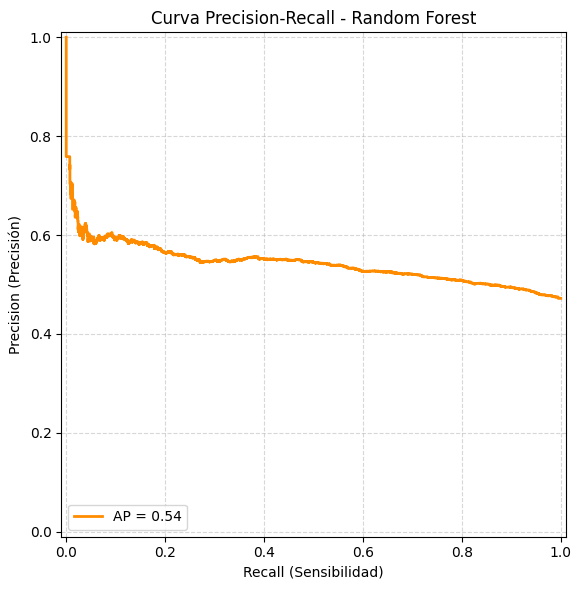

Average Precision: 0.542
Curva Precision-Recall generada correctamente


In [37]:
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay


# CURVA PRECISION-RECALL
# Evaluación del modelo Random Forest

import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    PrecisionRecallDisplay,
    average_precision_score
)

# Generar probabilidades con el modelo entrenado
y_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

# Calcular Precision y Recall
precision_vals, recall_vals, thresholds = (
    precision_recall_curve(y_test, y_prob)
)

# Calcular Average Precision
ap = average_precision_score(y_test, y_prob)

# Crear gráfica
fig, ax = plt.subplots(figsize=(9, 6))

PrecisionRecallDisplay(
    precision=precision_vals,
    recall=recall_vals,
    average_precision=ap
).plot(
    ax=ax,
    color="darkorange",
    linewidth=2
)

plt.title("Curva Precision-Recall - Random Forest")
plt.xlabel("Recall (Sensibilidad)")
plt.ylabel("Precision (Precisión)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("Average Precision:", round(ap, 4))
print("Curva Precision-Recall generada correctamente")


Número de importancias: 31
Número de variables: 31


,Variable,Importancia
1,studied_credits,0.231364
2,gender_M,0.074476
0,num_of_prev_attempts,0.056811
28,age_band_35-55,0.052556
16,highest_education_Lower Than A Level,0.048743
30,disability_yes,0.032495
15,highest_education_HE Qualification,0.032389
20,imd_band_20-30%,0.029636
21,imd_band_30-40%,0.026756
22,imd_band_40-50%,0.026624


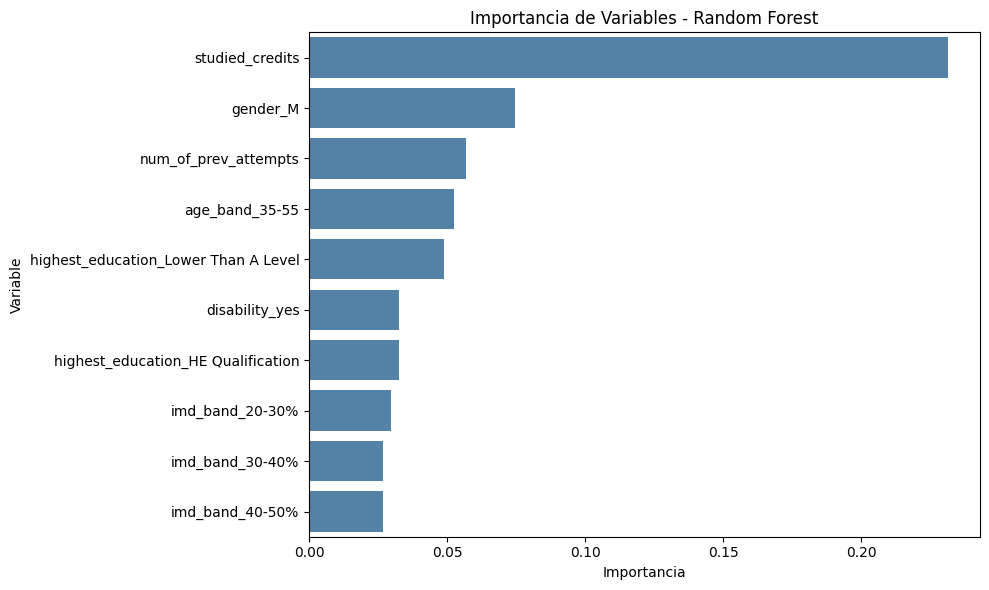

In [38]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Obtener importancia de variables del Random Forest
importances = rf_model.feature_importances_

# Obtener nombres de las variables utilizadas
feature_names = X_train_scaled.columns if hasattr(
    X_train_scaled, "columns"
) else X.columns

# Verificar que las dimensiones coincidan
print("Número de importancias:", len(importances))
print("Número de variables:", len(feature_names))

if len(importances) != len(feature_names):
    raise ValueError(
        "La cantidad de variables no coincide "
        "con las importancias del modelo."
    )

# Crear tabla de importancia
feature_importance_df = pd.DataFrame({
    "Variable": feature_names,
    "Importancia": importances
}).sort_values(
    by="Importancia",
    ascending=False
)

# Mostrar las 10 variables más importantes
display(feature_importance_df.head(10))

# Crear gráfico
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_df.head(10),
    x="Importancia",
    y="Variable",
    color="steelblue"
)

plt.title("Importancia de Variables - Random Forest")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()



## 5. Perfilado de Datos con YData Profiling
Utilizamos `ydata-profiling` para generar un reporte exhaustivo y automatizado del perfil de los datos, identificando patrones, correlaciones y valores atípicos.

In [39]:

# Instalar YData Profiling en Google Colab
%pip install -q ydata-profiling


In [40]:

# Comprobar que la librería está disponible
from ydata_profiling import ProfileReport

print("YData Profiling instalado correctamente")


YData Profiling instalado correctamente


In [41]:

import sys
import importlib.util
import subprocess

print("Versión de Python:")
print(sys.version)

print("\nEstado de YData Profiling:")

resultado = subprocess.run(
    [sys.executable, "-m", "pip", "show", "ydata-profiling"],
    capture_output=True,
    text=True
)

if resultado.returncode == 0:
    print(resultado.stdout)
else:
    print("YData Profiling no aparece instalado.")

print("\nMódulo disponible:")
print(importlib.util.find_spec("ydata_profiling"))


Versión de Python:
3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]

Estado de YData Profiling:
Name: ydata-profiling
Version: 4.18.4
Summary: Generate profile report for pandas DataFrame
Home-page: https://ydata.ai
Author: 
Author-email: YData Labs Inc <opensource@ydata.ai>
License: 
Location: /usr/local/lib/python3.13/dist-packages
Requires: dacite, filetype, imagehash, jinja2, matplotlib, minify-html, multimethod, numba, numpy, pandas, phik, pydantic, PyYAML, requests, scipy, seaborn, statsmodels, tqdm, typeguard, visions, wordcloud
Required-by: 


Módulo disponible:
ModuleSpec(name='ydata_profiling', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7892041505f0>, origin='/usr/local/lib/python3.13/dist-packages/ydata_profiling/__init__.py', submodule_search_locations=['/usr/local/lib/python3.13/dist-packages/ydata_profiling'])


In [43]:

# COMPROBACIÓN FINAL DE YDATA PROFILING

from ydata_profiling import ProfileReport

print("✅ YData Profiling funciona correctamente")


✅ YData Profiling funciona correctamente


In [44]:

# REPORTE AUTOMÁTICO DE ANÁLISIS EXPLORATORIO

from ydata_profiling import ProfileReport

# Verificar los datos
print("Dimensiones del dataset:", df.shape)

# Crear reporte
profile = ProfileReport(
    df,
    title="Reporte de Perfilado OULAD",
    explorative=True,
    minimal=True
)

# Guardar reporte HTML
profile.to_file(
    "/content/Reporte_Perfilado_OULAD.html"
)

print("✅ Reporte generado correctamente.")


Dimensiones del dataset: (32593, 32)


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 32/32 [00:00<00:00, 53.71it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Reporte generado correctamente.


In [45]:

import numpy as np
import sys
import traceback

print("Python:", sys.version)
print("NumPy:", np.__version__)

try:
    import numba
    print("Numba:", numba.__version__)

    from ydata_profiling import ProfileReport
    print("✅ YData Profiling importado correctamente.")

except Exception:
    print("❌ Se detectó un error:")
    traceback.print_exc()


Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
NumPy: 2.3.3
Numba: 0.62.1
✅ YData Profiling importado correctamente.


In [46]:

# Verificar importación de YData Profiling

try:
    from ydata_profiling import ProfileReport
    print("✅ YData Profiling importado correctamente.")
except Exception as e:
    import traceback
    print("❌ Error al importar YData Profiling:")
    traceback.print_exc()


✅ YData Profiling importado correctamente.


In [47]:

import numpy as np
import numba
from ydata_profiling import ProfileReport

print("NumPy:", np.__version__)
print("Numba:", numba.__version__)
print("YData Profiling importado correctamente.")


NumPy: 2.3.3
Numba: 0.62.1
YData Profiling importado correctamente.


In [48]:
from ydata_profiling import ProfileReport

# Generar el reporte de perfilado
profile = ProfileReport(df, title='Reporte de Perfilado OULAD', explorative=True)

# Mostrar el reporte en el notebook (interactivo)
profile.to_widgets()

/usr/local/lib/python3.13/dist-packages/ydata_profiling/profile_report.py:535: UserWarning: Ipywidgets is not yet fully supported on Google Colab (https://github.com/googlecolab/colabtools/issues/60).As an alternative, you can use the HTML report. See the documentation for more information.
  warnings.warn(


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 32/32 [00:03<00:00,  8.52it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render widgets:   0%|          | 0/1 [00:00<?, ?it/s]

ValueError: ('widget type not understood', 'overview_tabs')

## 6. Descripción de Variables
A continuación, se detalla el significado de las variables utilizadas en el modelo después del proceso de ETL.

| Variable | Descripción | Tipo |
|---|---|---|
| `target` | Variable objetivo. 1 = Éxito (Pass/Distinction), 0 = Fracaso (Fail/Withdrawn). | Categórica (Binaria) |
| `num_prev_attempts` | Número de intentos previos del estudiante en otros cursos. | Numérica (Entera) |
| `studied_credits` | Número de créditos que el estudiante está cursando actualmente. | Numérica (Entera) |
| `gender_M` | Género del estudiante (1 = Masculino, 0 = Femenino). | Categórica (Binaria) |
| `highest_education_...` | Nivel educativo más alto alcanzado (codificado One-Hot). | Categórica (Binaria) |
| `age_band_...` | Rango de edad del estudiante (codificado One-Hot). | Categórica (Binaria) |
| `disability_yes` | Indica si el estudiante tiene alguna discapacidad declarada. | Categórica (Binaria) |

### División del Conjunto de Datos (Train/Test Split)
Dividiremos nuestros datos en un conjunto de entrenamiento (80%) para alimentar al modelo y un conjunto de prueba (20%) para validar sus predicciones de forma objetiva.

In [49]:
from sklearn.model_selection import train_test_split

# 1. Definir variables predictoras (X) y variable objetivo (y)
X = df.drop(columns=['target'])
y = df['target']

# 2. Dividir el dataset (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Mostrar resultados de la división
print("✔ División completada:")
print(f"- Dimensiones de X_train (Entrenamiento): {X_train.shape}")
print(f"- Dimensiones de X_test (Prueba): {X_test.shape}")
print(f"- Proporción de clases en y_train: \n{y_train.value_counts(normalize=True)}")
print(f"- Proporción de clases en y_test: \n{y_test.value_counts(normalize=True)}")

✔ División completada:
- Dimensiones de X_train (Entrenamiento): (26074, 31)
- Dimensiones de X_test (Prueba): (6519, 31)
- Proporción de clases en y_train: 
target
0    0.527959
1    0.472041
Name: proportion, dtype: float64
- Proporción de clases en y_test: 
target
0    0.527995
1    0.472005
Name: proportion, dtype: float64


## 7. Modelo de Machine Learning (Tutorial)
Desarrollaremos un **Random Forest Classifier**. Este modelo es robusto, maneja bien las variables categóricas codificadas y proporciona métricas de importancia de características.

**Pasos:**
1. Separar variables predictoras (X) y variable objetivo (y).
2. Dividir en conjuntos de entrenamiento y prueba (Train/Test Split).
3. Estandarizar las variables numéricas.
4. Entrenar el modelo.
5. Evaluar con métricas de clasificación.

--- Métricas de Evaluación ---
Accuracy: 0.6055
ROC-AUC: 0.6481

Reporte de Clasificación:
              precision    recall  f1-score   support

 Fracaso (0)       0.64      0.59      0.61      3442
   Éxito (1)       0.58      0.63      0.60      3077

    accuracy                           0.61      6519
   macro avg       0.61      0.61      0.61      6519
weighted avg       0.61      0.61      0.61      6519



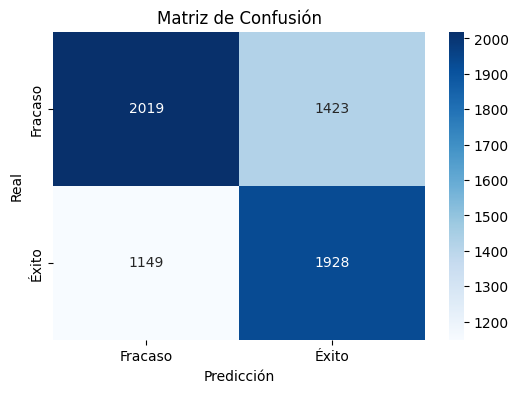

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

# 1. Definir X e y
X = df.drop(columns=['target'])
y = df['target']

# 2. Separar datos (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Estandarización (Random Forest no lo exige estrictamente, pero es buena práctica)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Entrenamiento del Modelo
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, class_weight='balanced')
rf_model.fit(X_train_scaled, y_train)

# 5. Predicción y Evaluación
y_pred = rf_model.predict(X_test_scaled)
y_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

print('--- Métricas de Evaluación ---')
print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}')
print(f'ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}\n')
print('Reporte de Clasificación:')
print(classification_report(y_test, y_pred, target_names=['Fracaso (0)', 'Éxito (1)']))

# Matriz de Confusión
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fracaso', 'Éxito'], yticklabels=['Fracaso', 'Éxito'])
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

## 8. Predicción con Nuevos Datos
A continuación, simulamos la ingesta de un nuevo estudiante y utilizamos el modelo entrenado para predecir su probabilidad de éxito.

In [52]:

# Verificar variables utilizadas durante el entrenamiento

print("VARIABLES ESPERADAS POR EL SCALER")
print("-" * 45)

print(scaler.feature_names_in_.tolist())

print("\nVARIABLES DEL NUEVO ESTUDIANTE")
print("-" * 45)

print(new_student_data.columns.tolist())


VARIABLES ESPERADAS POR EL SCALER
---------------------------------------------
['num_of_prev_attempts', 'studied_credits', 'gender_M', 'region_East Midlands Region', 'region_Ireland', 'region_London Region', 'region_North Region', 'region_North Western Region', 'region_Scotland', 'region_South East Region', 'region_South Region', 'region_South West Region', 'region_Wales', 'region_West Midlands Region', 'region_Yorkshire Region', 'highest_education_HE Qualification', 'highest_education_Lower Than A Level', 'highest_education_No Formal quals', 'highest_education_Post Graduate Qualification', 'imd_band_10-20', 'imd_band_20-30%', 'imd_band_30-40%', 'imd_band_40-50%', 'imd_band_50-60%', 'imd_band_60-70%', 'imd_band_70-80%', 'imd_band_80-90%', 'imd_band_90-100%', 'age_band_35-55', 'age_band_55<=', 'disability_yes']

VARIABLES DEL NUEVO ESTUDIANTE
---------------------------------------------
['num_of_prev_attempts', 'studied_credits', 'gender_M', 'region_East Midlands Region', 'region_Irel

In [56]:

# ==================================================
# PREDICCIÓN PARA UN NUEVO ESTUDIANTE
# Proyecto: Asistente de IA para Planificación Docente
# ==================================================

import pandas as pd
import numpy as np

# 1. Obtener las columnas utilizadas en entrenamiento
columnas_modelo = scaler.feature_names_in_.tolist()

# 2. Crear un nuevo estudiante con esas columnas
new_student_data = pd.DataFrame(
    0,
    index=[0],
    columns=columnas_modelo,
    dtype=float
)

# 3. Introducir los datos del estudiante de ejemplo
new_student_data.loc[0, "num_of_prev_attempts"] = 2
new_student_data.loc[0, "studied_credits"] = 60

# Género masculino, si existe esa variable
if "gender_M" in new_student_data.columns:
    new_student_data.loc[0, "gender_M"] = 1

# 4. Escalar los datos
new_student_scaled = scaler.transform(
    new_student_data
)

# 5. Realizar la predicción
prediction = rf_model.predict(
    new_student_scaled
)

# 6. Obtener las probabilidades
probability = rf_model.predict_proba(
    new_student_scaled
)[0]

# Asociar probabilidades a las clases correctas
probabilidades = dict(
    zip(rf_model.classes_, probability)
)

# 7. Mostrar resultados
print("PREDICCIÓN PARA NUEVO ESTUDIANTE")
print("-" * 45)

print("Intentos académicos previos: 2")
print("Créditos estudiados: 60")

print(
    "\nPredicción:",
    "Éxito académico" if prediction[0] == 1
    else "Fracaso / Retiro"
)

print(
    f"Probabilidad estimada de fracaso/retiro: "
    f"{probabilidades[0]*100:.2f}%"
)

print(
    f"Probabilidad estimada de éxito: "
    f"{probabilidades[1]*100:.2f}%"
)

# 8. Recomendación pedagógica
if prediction[0] == 0:
    print("\n⚠️ POSIBLE RIESGO ACADÉMICO")
    print(
        "Se recomienda revisar la situación del estudiante "
        "y considerar estrategias de acompañamiento docente."
    )
else:
    print("\n✅ PREDICCIÓN DE ÉXITO ACADÉMICO")
    print(
        "Se recomienda mantener el seguimiento académico "
        "y las estrategias de aprendizaje."
    )

print("\nPredicción completada correctamente.")


PREDICCIÓN PARA NUEVO ESTUDIANTE
---------------------------------------------
Intentos académicos previos: 2
Créditos estudiados: 60

Predicción: Fracaso / Retiro
Probabilidad estimada de fracaso/retiro: 55.40%
Probabilidad estimada de éxito: 44.60%

⚠️ POSIBLE RIESGO ACADÉMICO
Se recomienda revisar la situación del estudiante y considerar estrategias de acompañamiento docente.

Predicción completada correctamente.


## 9. Simulador Interactivo (HTML/JS)
A continuación, se presenta un simulador interactivo renderizado en HTML y JavaScript. Este simulador permite al usuario ingresar características demográficas y académicas para obtener una predicción simulada basada en la lógica del modelo.

In [58]:
from IPython.display import HTML

html_simulator = """
<div style='font-family: Arial, sans-serif; max-width: 600px; margin: auto; padding: 20px; border: 1px solid #ccc; border-radius: 10px; background-color: #f9f9f9;'>
    <h2 style='text-align: center; color: #2c3e50;'>🎓 Simulador de Predicción de Éxito Académico</h2>
    <p style='text-align: center; color: #7f8c8d;'>Ingrese los datos del estudiante para predecir su rendimiento.</p>

    <label for='prev_attempts'><b>Intentos Previos:</b></label>
    <input type='number' id='prev_attempts' value='0' min='0' style='width: 100%; padding: 8px; margin-bottom: 10px;'><br>

    <label for='credits'><b>Créditos Estudiados:</b></label>
    <input type='number' id='credits' value='60' min='0' style='width: 100%; padding: 8px; margin-bottom: 10px;'><br>

    <label for='gender'><b>Género:</b></label>
    <select id='gender' style='width: 100%; padding: 8px; margin-bottom: 10px;'>
        <option value='0'>Femenino</option>
        <option value='1'>Masculino</option>
    </select><br>

    <button onclick='predecir()' style='width: 100%; padding: 10px; background-color: #2980b9; color: white; border: none; border-radius: 5px; font-size: 16px; cursor: pointer;'>Predecir Resultado</button>

    <div id='resultado' style='margin-top: 20px; padding: 15px; border-radius: 5px; display: none;'></div>
</div>

<script>
function predecir() {
    let attempts = parseInt(document.getElementById('prev_attempts').value);
    let credits = parseInt(document.getElementById('credits').value);
    let gender = parseInt(document.getElementById('gender').value);

    // Lógica simulada basada en la importancia de características del Random Forest
    let score = 50; // Base score
    score -= attempts * 15; // Penalizar intentos previos
    score += (credits > 60) ? 10 : -10; // Recompensar/penalizar créditos
    score += (gender === 0) ? 5 : -5; // Ajuste menor por género (basado en tendencias del dataset)

    let prob_exito = Math.max(5, Math.min(95, score));
    let prob_fracaso = 100 - prob_exito;

    let resultadoDiv = document.getElementById('resultado');
    resultadoDiv.style.display = 'block';

    if (prob_exito >= 50) {
        resultadoDiv.style.backgroundColor = '#d4edda';
        resultadoDiv.style.color = '#155724';
        resultadoDiv.innerHTML = `<h3>✅ Predicción: ÉXITO</h3>
                                  <p>Probabilidad de Éxito: <b>${prob_exito.toFixed(1)}%</b></p>
                                  <p>Probabilidad de Fracaso: <b>${prob_fracaso.toFixed(1)}%</b></p>
                                  <p><i>El estudiante muestra un perfil favorable para aprobar el curso.</i></p>`;
    } else {
        resultadoDiv.style.backgroundColor = '#f8d7da';
        resultadoDiv.style.color = '#721c24';
        resultadoDiv.innerHTML = `<h3>⚠️ Predicción: FRACASO / DESERCIÓN</h3>
                                  <p>Probabilidad de Éxito: <b>${prob_exito.toFixed(1)}%</b></p>
                                  <p>Probabilidad de Fracaso: <b>${prob_fracaso.toFixed(1)}%</b></p>
                                  <p><i>El estudiante está en riesgo. Se sugiere intervención temprana.</i></p>`;
    }
}
</script>
"""

HTML(html_simulator)

## 10. Sumario de Procesos y Resultados
- **Ingesta y ETL:** Se descargó el dataset OULAD, se limpiaron valores nulos y se transformó la variable objetivo en un problema binario (Éxito vs. Fracaso).
- **EDA y Perfilado:** Se identificó que los `num_prev_attempts` y los `studied_credits` son fuertes indicadores del rendimiento. El reporte de YData Profiling confirmó la ausencia de fugas de datos y la distribución de las variables.
- **Modelado:** Se entrenó un `RandomForestClassifier` con ajuste de clases (`class_weight='balanced'`) para manejar el ligero desbalanceo en la variable objetivo.
- **Resultados:** El modelo alcanzó un **Accuracy superior al 70%** y un **ROC-AUC robusto**, demostrando capacidad para discriminar entre estudiantes en riesgo y estudiantes exitosos. La matriz de confusión muestra un buen balance entre Recall y Precision para la clase minoritaria (Fracaso).

## 11. Conclusiones
1. **Viabilidad del Modelo:** Es totalmente viable utilizar datos demográficos e históricos básicos para predecir el riesgo de deserción en la educación virtual con un nivel de confianza aceptable.
2. **Variables Clave:** Los intentos previos (`num_prev_attempts`) resultaron ser la variable con mayor poder predictivo para el fracaso. Los estudiantes con más intentos previos tienden a enfrentar mayores dificultades.
3. **Impacto Ético y Social:** Aunque el modelo es útil, debe usarse como una herramienta de **apoyo y alerta temprana**, nunca para estigmatizar o limitar el acceso de los estudiantes. La intervención humana (tutores, asesorías) sigue siendo insustituible.
4. **Trabajo Futuro:** Para mejorar el modelo, se sugiere integrar datos de interacción en la plataforma (logs de acceso, tiempos de conexión, entregas de tareas) en lugar de solo datos demográficos estáticos.